# LeakLens — Model 1: Loss-Risk Classifier

**Goal:** Predict whether a completed sale will lose money.

**Approach:**
1. Start with a simple Decision Tree
2. Check train vs test performance
3. If it underfits → try Random Forest
4. If it overfits → simplify the tree
5. Measure with AUC, Precision, Recall, and Top-10% hit rate

**Important rule:** Never use `unit_cost` or `profit` as features (they give the answer away).

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    classification_report,
    RocCurveDisplay
)
import joblib
from pathlib import Path

DATA_DIR = Path("../data")
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
print("Libraries loaded.")

Libraries loaded.


## 2. Load the five CSV files

In [12]:
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
transactions = pd.read_csv(DATA_DIR / "transactions.csv")
inventory = pd.read_csv(DATA_DIR / "inventory.csv")
campaigns = pd.read_csv(DATA_DIR / "campaigns.csv")

print("customers    :", customers.shape)
print("products     :", products.shape)
print("transactions :", transactions.shape)
print("inventory    :", inventory.shape)
print("campaigns    :", campaigns.shape)

customers    : (3000, 5)
products     : (250, 5)
transactions : (18000, 10)
inventory    : (5000, 7)
campaigns    : (1200, 8)


## 3. Build the modeling table

Keep only **Completed** transactions.  
Join products and customers.

In [13]:
tx = transactions[transactions["status"] == "Completed"].copy()
print("Completed transactions:", len(tx))

df = tx.merge(products, on="product_id", how="left")
df = df.merge(customers, on="customer_id", how="left")

print("After joins:", df.shape)
df.head()

Completed transactions: 13962
After joins: (13962, 18)


,transaction_id,customer_id,product_id,timestamp,quantity,unit_price,discount_pct,status,channel,payment_method,category,unit_cost,list_price,supplier_lead_days,region,customer_segment,signup_date,preferred_channel
0,TX000001,CU01588,PR0103,2025-08-22 12:30:00,5,307.70,0.20,Completed,App,Card,Electronics,63.55,384.62,8,West,New,2023-09-05,App
1,TX000002,CU00382,PR0101,2025-06-06 04:03:00,4,346.98,0.00,Completed,Web,Card,Home,15.38,346.98,18,North,Returning,2024-06-15,Web
2,TX000005,CU01792,PR0022,2025-06-18 02:13:00,5,361.56,0.05,Completed,Store,Cash,Home,104.19,380.59,7,East,Loyal,2023-04-11,Store
3,TX000006,CU02380,PR0148,2025-01-10 22:42:00,4,147.69,0.15,Completed,App,Cash,Electronics,47.79,173.75,12,West,At-risk,2024-01-24,Web
4,TX000007,CU01351,PR0024,2025-02-18 05:24:00,5,329.91,0.10,Completed,Web,Card,Electronics,19.06,366.57,1,South,At-risk,2023-06-25,Web


## 4. Create the target: `loses_money`

profit = quantity × unit_price × (1 − discount_pct/100) − quantity × unit_cost  
loses_money = 1 if profit < 0 else 0

In [14]:
df["revenue"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100.0)
df["profit"] = df["revenue"] - (df["quantity"] * df["unit_cost"])
df["loses_money"] = (df["profit"] < 0).astype(int)

print("Loss rate among completed sales:")
print(df["loses_money"].value_counts(normalize=True).round(3))
print("Total loss-making sales:", df["loses_money"].sum())

Loss rate among completed sales:
loses_money
0    0.658
1    0.342
Name: proportion, dtype: float64
Total loss-making sales: 4775


## 5. Choose features (NO cost, NO profit)

In [15]:
candidates = [
    "unit_price", "list_price", "discount_pct", "quantity",
    "supplier_lead_days", "category", "channel",
    "region", "customer_segment", "payment_method"
]

feature_cols = [c for c in candidates if c in df.columns]
print("Features we will use:")
print(feature_cols)

X_raw = df[feature_cols].copy()
y = df["loses_money"].copy()

Features we will use:
['unit_price', 'list_price', 'discount_pct', 'quantity', 'supplier_lead_days', 'category', 'channel', 'region', 'customer_segment', 'payment_method']


## 6. Encode categorical columns

In [16]:
cat_cols = X_raw.select_dtypes(include=["object"]).columns.tolist()
num_cols = X_raw.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical:", cat_cols)
print("Numeric    :", num_cols)

encoders = {}
X = X_raw.copy()

for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    encoders[col] = le

print("Encoding done.")
X.head()

Categorical: ['category', 'channel', 'region', 'customer_segment', 'payment_method']
Numeric    : ['unit_price', 'list_price', 'discount_pct', 'quantity', 'supplier_lead_days']
Encoding done.


,unit_price,list_price,discount_pct,quantity,supplier_lead_days,category,channel,region,customer_segment,payment_method
0,307.70,384.62,0.20,5,8,1,0,4,2,0
1,346.98,346.98,0.00,4,18,4,2,2,3,0
2,361.56,380.59,0.05,5,7,4,1,1,1,1
3,147.69,173.75,0.15,4,12,1,0,4,0,1
4,329.91,366.57,0.10,5,1,1,2,3,0,0


## 7. Train / Test split

Prefer time-based split if a date column exists.

In [17]:
date_col = None
for c in ["timestamp", "date", "order_date", "transaction_date"]:
    if c in df.columns:
        date_col = c
        break

if date_col is not None:
    df["_date"] = pd.to_datetime(df[date_col], errors="coerce")
    cutoff = df["_date"].quantile(0.75)
    train_mask = df["_date"] <= cutoff
    test_mask  = df["_date"] > cutoff
    X_train, X_test = X.loc[train_mask], X.loc[test_mask]
    y_train, y_test = y.loc[train_mask], y.loc[test_mask]
    print(f"Time-based split using '{date_col}'")
    print(f"Cutoff: {cutoff}")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )
    print("Random stratified split (no date column found)")

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")
print(f"Train loss rate: {y_train.mean():.3f} | Test loss rate: {y_test.mean():.3f}")

Time-based split using 'timestamp'
Cutoff: 2025-09-28 20:47:45
Train size: 10471 | Test size: 3491
Train loss rate: 0.341 | Test loss rate: 0.345


## 8. Baseline

In [18]:
print("Baseline AUC (random ranking): 0.50")
print("Majority-class accuracy:", round((y_test == 0).mean(), 3))

Baseline AUC (random ranking): 0.50
Majority-class accuracy: 0.655


## 9. Model A — Decision Tree (start simple)

In [19]:
tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=30,
    random_state=42
)
tree.fit(X_train, y_train)

train_prob = tree.predict_proba(X_train)[:, 1]
test_prob  = tree.predict_proba(X_test)[:, 1]
train_pred = tree.predict(X_train)
test_pred  = tree.predict(X_test)

print("=== Decision Tree ===")
print(f"Train AUC : {roc_auc_score(y_train, train_prob):.3f}")
print(f"Test  AUC : {roc_auc_score(y_test, test_prob):.3f}")
print(f"Test Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Test Recall   : {recall_score(y_test, test_pred):.3f}")
print()
print(classification_report(y_test, test_pred, target_names=["Profit", "Loss"]))

=== Decision Tree ===
Train AUC : 0.966
Test  AUC : 0.965
Test Precision: 0.971
Test Recall   : 0.745

              precision    recall  f1-score   support

      Profit       0.88      0.99      0.93      2286
        Loss       0.97      0.75      0.84      1205

    accuracy                           0.90      3491
   macro avg       0.93      0.87      0.89      3491
weighted avg       0.91      0.90      0.90      3491



## 10. Check underfit / overfit

In [20]:
train_auc = roc_auc_score(y_train, train_prob)
test_auc  = roc_auc_score(y_test, test_prob)
gap = train_auc - test_auc

print(f"Train AUC: {train_auc:.3f}")
print(f"Test  AUC: {test_auc:.3f}")
print(f"Gap      : {gap:.3f}")

if train_auc < 0.70 and test_auc < 0.70:
    decision = "UNDERFIT → try Random Forest"
elif gap > 0.08:
    decision = "OVERFIT → simplify the tree (lower max_depth)"
else:
    decision = "GOOD → Decision Tree is enough"

print("Decision:", decision)

Train AUC: 0.966
Test  AUC: 0.965
Gap      : 0.001
Decision: GOOD → Decision Tree is enough


## 11. Business metric — Top 10% hit rate

In [21]:
def top10_hit_rate(y_true, y_prob):
    n = max(1, int(0.10 * len(y_true)))
    top_idx = np.argsort(y_prob)[-n:]
    return y_true.iloc[top_idx].mean()


final_prob = test_prob
final_model_name = "DecisionTree"

hit = top10_hit_rate(y_test, final_prob)
print(f"Model used       : {final_model_name}")
print(f"Top-10% hit rate : {hit:.1%}")

Model used       : DecisionTree
Top-10% hit rate : 100.0%


## 12. Feature importance

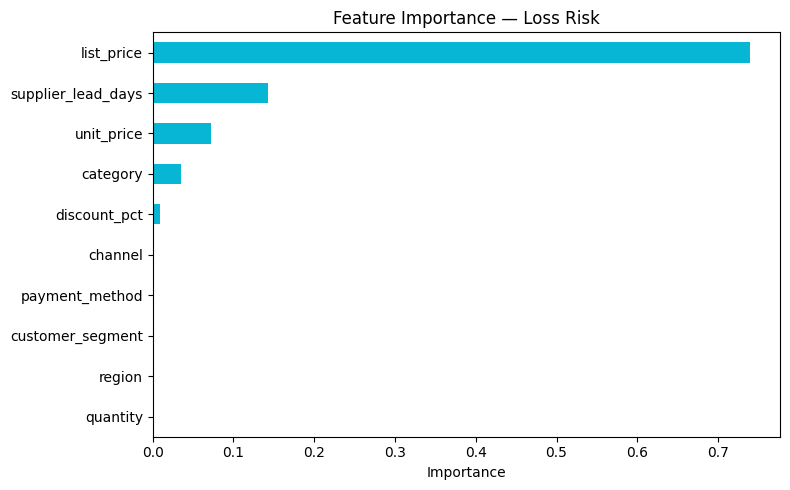

list_price            0.739711
supplier_lead_days    0.142534
unit_price            0.072508
category              0.035544
discount_pct          0.009321
channel               0.000383
quantity              0.000000
region                0.000000
customer_segment      0.000000
payment_method        0.000000
dtype: float64


In [22]:
importances = pd.Series(tree.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind="barh", color="#06b6d4")
plt.title("Feature Importance — Loss Risk")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

## 13. ROC Curve

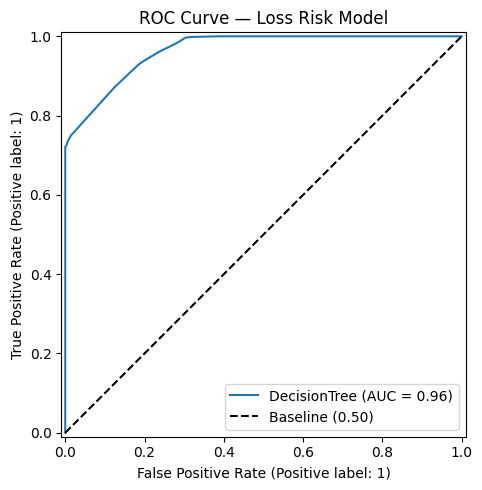

In [23]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, final_prob, ax=ax, name=final_model_name)
ax.plot([0, 1], [0, 1], "k--", label="Baseline (0.50)")
ax.legend()
ax.set_title("ROC Curve — Loss Risk Model")
plt.tight_layout()
plt.show()

## 14. Save the final model

In [24]:
final_model = tree   

bundle = {
    "model": final_model,
    "encoders": encoders,
    "feature_cols": feature_cols,
    "model_name": final_model_name,
    "test_auc": float(roc_auc_score(y_test, final_prob)),
    "top10_hit_rate": float(hit),
}

save_path = MODEL_DIR / "loss_risk_model.joblib"
joblib.dump(bundle, save_path)

print(f"Model saved to : {save_path}")
print(f"Test AUC       : {bundle['test_auc']:.3f}")
print(f"Top-10% hit    : {bundle['top10_hit_rate']:.1%}")

Model saved to : ..\models\loss_risk_model.joblib
Test AUC       : 0.965
Top-10% hit    : 100.0%
